In [ ]:
# Core Langgraph Frameworks
!pip install langgraph
!pip install langchain-openai
!pip install langchain
!pip install pydantic
!pip install grandalf


In [ ]:
# Import all depedencies

import operator
from typing import Annotated, Literal, TypedDict
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from IPython.display import display,Image

In [ ]:
# Set up OpenAI API Key
# Please make sure you have your OpenAI API key stored as a secret named 'OPENAI_API_KEY'
import os
from google.colab import userdata

os.environ["OPENAI_API_KEY"] = userdata.get('OPENAI_APIKEY')

In [ ]:
# ==========================================
# Step 1: Initialize LLM
# ==========================================
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)


In [27]:
# ===============================================================
# Step 2: Setup Structured output schema for the Supervisor LLM
# =================================================================

class SupervisorDecision(BaseModel):
    next_node: Literal["researcher", "analyst", "synthesizer"] = Field(
        description="Select 'researcher' for facts, 'analyst' for metrics, or 'synthesizer' if ready to finish."
    )
    reasoning: str = Field(description="Explanation of why this node was chosen.")

In [28]:
# ==========================================
# Step 3: Setup State
# ==========================================

class GraphState(TypedDict):
    task: str
    findings: Annotated[list[str], operator.add]
    next_step: str
    final_report: str

In [29]:
# ==========================================
# Step 3: Setup Researcher Agent
# ==========================================

def researcher_agent(state: GraphState):
    # Simulated work output
    print("-"*80)
    print(f"state passed to researcher_agent is {state}")
    print("-"*80)
    return {"findings": ["Market Fact: Cloud infrastructure spending grew 22% YoY in Q3."]}

In [30]:
# ==========================================
# Step 3: Setup Analyst Agent
# ==========================================

def analyst_agent(state: GraphState):
    # Simulated work output
    print("-"*80)
    print(f"state passed to analyst_agent is {state}")
    print("-"*80)
    return {"findings": ["Metric Insight: Growth was primarily driven by enterprise AI adoption."]}

In [31]:
# ==========================================
# Step 4: Setup Supervisor Agent
# ==========================================

def supervisor_agent(state: GraphState):
    structured_llm = llm.with_structured_output(SupervisorDecision)
    prompt = f"""
    You are the Lead Orchestrator for the task: '{state['task']}'.
    Findings collected so far: {state.get('findings', [])}

    Determine the next node to execute:
    - 'researcher': If background facts/data are still needed.
    - 'analyst': If metrics or technical insights are needed.
    - 'synthesizer': ONLY when sufficient findings exist to construct the final report.
    """
    decision = structured_llm.invoke(prompt)
    print("")
    print("-"*80)
    print(f"state passed to supervisor_agent is {state}")
    print(f"decision via supervisor_agent -> {decision}")
    print("-"*80)
    return {"next_step": decision.next_node}

In [32]:
# ==========================================
# Step 5: Setup Synthesizer Agent
# ==========================================

def synthesizer_agent(state: GraphState):
    # Aggregate all state findings into a single prompt context
    collected_findings = "\n- ".join(state["findings"])

    prompt = f"""
    You are the Lead Synthesizer. Merge the following research findings into a
    cohesive executive summary for the topic: '{state['task']}'.

    Findings:
    - {collected_findings}
    """
    print("-"*80)
    print(f"state passed to synthesizer_agent is {state}")
    response = llm.invoke(prompt)
    return {"final_report": response.content}
    print("-"*80)

In [33]:
# ==========================================
# Step 6: Setup Routing Function
# ==========================================

def route_next(state: GraphState) -> str:
    print("-"*80)
    print("State of Next-Step is ", state["next_step"])
    print("-"*80)
    return state["next_step"]

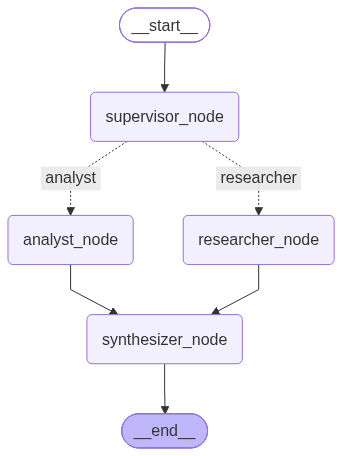

In [34]:

# ==========================================
# Step 7: Setup Graph
# ==========================================

workflow = StateGraph(GraphState)

# Add Nodes
workflow.add_node("supervisor_node", supervisor_agent)
workflow.add_node("researcher_node", researcher_agent)
workflow.add_node("analyst_node", analyst_agent)
workflow.add_node("synthesizer_node", synthesizer_agent)


# Add Edges
workflow.add_edge(START, "supervisor_node")
workflow.add_conditional_edges(
    "supervisor_node",
    route_next,
    {
        "researcher": "researcher_node",
        "analyst": "analyst_node"
    }
)
workflow.add_edge("researcher_node", "synthesizer_node")
workflow.add_edge("analyst_node", "synthesizer_node")
workflow.add_edge("synthesizer_node", END)


executor = workflow.compile()

display(Image(executor.get_graph().draw_mermaid_png()))


In [35]:
# ==========================================
# Step 8: Run the Graph
# ==========================================

inputs = {"task": "Analyze current cloud spending trends and driver factors."}
output = executor.invoke(inputs)
print("="*80)
print("FINAL REPORT:\n", output["final_report"])
print("="*80)


--------------------------------------------------------------------------------
state passed to supervisor_agent is {'task': 'Analyze current cloud spending trends and driver factors.', 'findings': []}
decision via supervisor_agent -> next_node='researcher' reasoning='Since there are no findings collected so far, we need to gather background facts and data on current cloud spending trends and driver factors before proceeding to analysis or synthesis.'
--------------------------------------------------------------------------------
--------------------------------------------------------------------------------
State of Next-Step is  researcher
--------------------------------------------------------------------------------
--------------------------------------------------------------------------------
state passed to researcher_agent is {'task': 'Analyze current cloud spending trends and driver factors.', 'findings': [], 'next_step': 'researcher'}
-----------------------------------